In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%pip install neuralforecast
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.0/294.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 831.6/831.6 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 56.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd

from google.colab import files
uploaded = files.upload()

Saving usd_idr_2020_2026.xlsx to usd_idr_2020_2026.xlsx


In [ ]:
data = pd.read_excel('usd_idr_2020_2026.xlsx',sheet_name="Sheet2",header = 0)
data = data[['ds', 'y', 'unique_id']]
data.head()

,ds,y,unique_id
0,2017-01-02,13512.0,IDR=X
1,2017-01-03,13506.0,IDR=X
2,2017-01-04,13443.0,IDR=X
3,2017-01-05,13348.0,IDR=X
4,2017-01-06,13319.0,IDR=X


In [ ]:
data['ds'] = pd.to_datetime(data['ds'])

train_df = data[data['ds'] < '2025-07-04']
test_df  = data[data['ds'] >= '2025-07-04']

# **Membangun Model**

In [ ]:
horizon = len(test_df)

models = [NHITS(h=horizon,
                learning_rate=0.0001,
                max_steps=100,
                input_size=84,
                n_pool_kernel_size=[4,2,1],
                n_blocks=[2,2,2],
                mlp_units=[[712,712]*3],
                scaler_type="minmax",
                )]

INFO:lightning_fabric.utilities.seed:Seed set to 1


In [ ]:
horizon

151

# **Melatih Model**

In [ ]:
nf = NeuralForecast(
    models=models,
    freq='B')

Y_hat_df = nf.fit(df=train_df, val_size=horizon)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.callbacks.model_summary:
  | Name         | Type          | Params | Mode 
-------------------------------------------------------
0 | loss         | MAE           | 0      | train
1 | padder_train | ConstantPad1d | 0      | train
2 | scaler       | TemporalNorm  | 0      | train
3 | blocks       | ModuleList    | 4.0 M  | train
-------------------------------------------------------
4.0 M     Trainable params
0         Non-trainable params
4.0 M     Total params
15.976    Total estimated model params size (MB)
52        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=100` reached.


# **Prediksi Data Latih**

In [ ]:
pred_train = nf.predict_insample()

pred_train_pick = (
    pred_train
    .groupby(['unique_id', 'ds'])['NHITS']
    .last()
    .reset_index()

)

train_with_pred = train_df.merge(
    pred_train_pick,
    on=['unique_id', 'ds'],
    how='left'
)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

In [ ]:
train_with_pred

,ds,y,unique_id,NHITS
0,2017-01-02,13512.000000,IDR=X,-inf
1,2017-01-03,13506.000000,IDR=X,1.340428e+04
2,2017-01-04,13443.000000,IDR=X,1.339422e+04
3,2017-01-05,13348.000000,IDR=X,1.328357e+04
4,2017-01-06,13319.000000,IDR=X,1.320764e+04
...,...,...,...,...
2214,2025-06-27,16222.799805,IDR=X,1.676571e+04
2215,2025-06-30,16229.000000,IDR=X,1.668758e+04
2216,2025-07-01,16230.000000,IDR=X,1.671495e+04
2217,2025-07-02,16236.400391,IDR=X,1.666479e+04


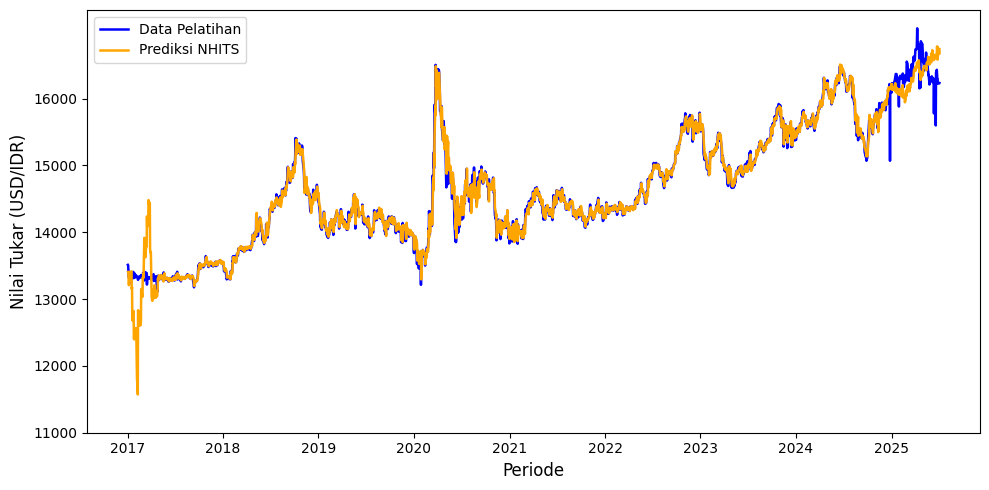

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

plt.plot(train_with_pred['ds'], train_with_pred['y'],
         color='blue',
         linewidth=1.8,
         label='Data Pelatihan')

plt.plot(train_with_pred['ds'], train_with_pred['NHITS'],
         color='orange',
         linewidth=1.8,
         label='Prediksi NHITS')

plt.xlabel('Periode', fontsize=12)
plt.ylabel('Nilai Tukar (USD/IDR)', fontsize=12)
plt.yticks(np.arange(11000, 17000, 1000))

plt.grid(False)
plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
from neuralforecast.losses.numpy import mape

print(
    'MAPE Train:',
    mape(
        train_with_pred['y'].iloc[1:],
        train_with_pred['NHITS'].iloc[1:]
    )
)

MAPE Train: 0.005970741302607628


In [ ]:
import numpy as np

print('Korelasi Pearson Train:', np.corrcoef(train_with_pred.replace([np.inf, -np.inf], np.nan).dropna()[['y', 'NHITS']].T)[0, 1])

Korelasi Pearson Train: 0.9823475889548877


# **Prediksi Data Uji**

In [ ]:
fcst = nf.predict(h=horizon)
fcst

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

,unique_id,ds,NHITS
0,IDR=X,2025-07-04,16284.756836
1,IDR=X,2025-07-07,16296.442383
2,IDR=X,2025-07-08,16268.779297
3,IDR=X,2025-07-09,16280.422852
4,IDR=X,2025-07-10,16354.743164
...,...,...,...
146,IDR=X,2026-01-26,17187.314453
147,IDR=X,2026-01-27,17272.935547
148,IDR=X,2026-01-28,17275.488281
149,IDR=X,2026-01-29,17247.306641


In [ ]:
result = pd.concat([
    test_df[['ds','y']].reset_index(drop=True),
    fcst[['NHITS']].reset_index(drop=True)
], axis=1)

print(result)
print(result.columns)

            ds             y         NHITS
0   2025-07-04  16203.700195  16284.756836
1   2025-07-07  16178.000000  16296.442383
2   2025-07-08  16318.900391  16268.779297
3   2025-07-09  16261.000000  16280.422852
4   2025-07-10  16235.000000  16354.743164
..         ...           ...           ...
146 2026-01-26  16770.000000  17187.314453
147 2026-01-27  16734.000000  17272.935547
148 2026-01-28  16674.699219  17275.488281
149 2026-01-29  16722.800781  17247.306641
150 2026-01-30  16778.300781  17223.980469

[151 rows x 3 columns]
Index(['ds', 'y', 'NHITS'], dtype='object')


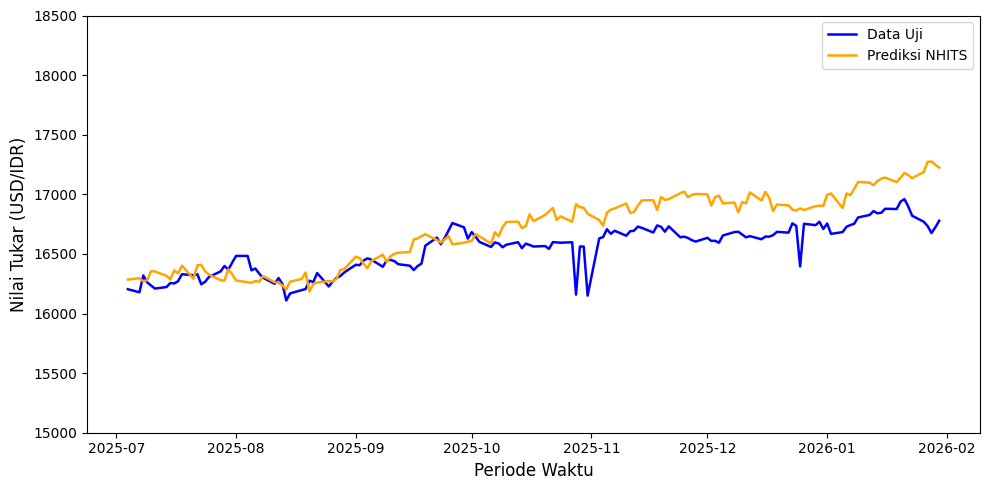

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(result['ds'], result['y'],
         color='blue',
         linewidth=1.8,
         label='Data Uji')

plt.plot(result['ds'], result['NHITS'],
         color='orange',
         linewidth=1.8,
         label='Prediksi NHITS')

plt.xlabel('Periode Waktu', fontsize=12)
plt.ylabel('Nilai Tukar (USD/IDR)', fontsize=12)
plt.yticks(np.arange(15000, 19000, 500))
plt.grid(False)
plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
import numpy as np
from neuralforecast.losses.numpy import mape, rmse

print('MAPE Test:', mape(result['y'], result['NHITS']))

MAPE Test: 0.011162592728637665


In [ ]:
import numpy as np

print('Korelasi Pearson Test:', np.corrcoef(result['y'], result['NHITS'])[0, 1])

Korelasi Pearson Test: 0.8532193813475408


# **Peramalan 7 Bulan Ke depan**

In [ ]:
nf_final = NeuralForecast(
    models=models,
    freq='B')

Y_hat_df_final = nf_final.fit(df=data, val_size=horizon)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.callbacks.model_summary:
  | Name         | Type          | Params | Mode 
-------------------------------------------------------
0 | loss         | MAE           | 0      | train
1 | padder_train | ConstantPad1d | 0      | train
2 | scaler       | TemporalNorm  | 0      | train
3 | blocks       | ModuleList    | 4.0 M  | train
-------------------------------------------------------
4.0 M     Trainable params
0         Non-trainable params
4.0 M     Total params
15.976    Total estimated model params size (MB)
52        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=100` reached.


In [ ]:
fcst_future = nf_final.predict(data, h=horizon)
fcst_future

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

,unique_id,ds,NHITS
0,IDR=X,2026-02-02,16783.322266
1,IDR=X,2026-02-03,16797.199219
2,IDR=X,2026-02-04,16795.064453
3,IDR=X,2026-02-05,16823.523438
4,IDR=X,2026-02-06,16821.177734
...,...,...,...
146,IDR=X,2026-08-25,17431.367188
147,IDR=X,2026-08-26,17450.804688
148,IDR=X,2026-08-27,17480.841797
149,IDR=X,2026-08-28,17479.154297


In [ ]:
data_ftr = pd.read_excel('usd_idr_2020_2026.xlsx',sheet_name="Sheet5",header = 0)
data_ftr = data_ftr[['ds', 'y', 'unique_id']]
data_ftr.head()

,ds,y,unique_id
0,2026-02-02,16758.400391,IDR=X
1,2026-02-03,16758.400391,IDR=X
2,2026-02-04,16759.000000,IDR=X
3,2026-02-05,16800.000000,IDR=X
4,2026-02-06,16879.900391,IDR=X


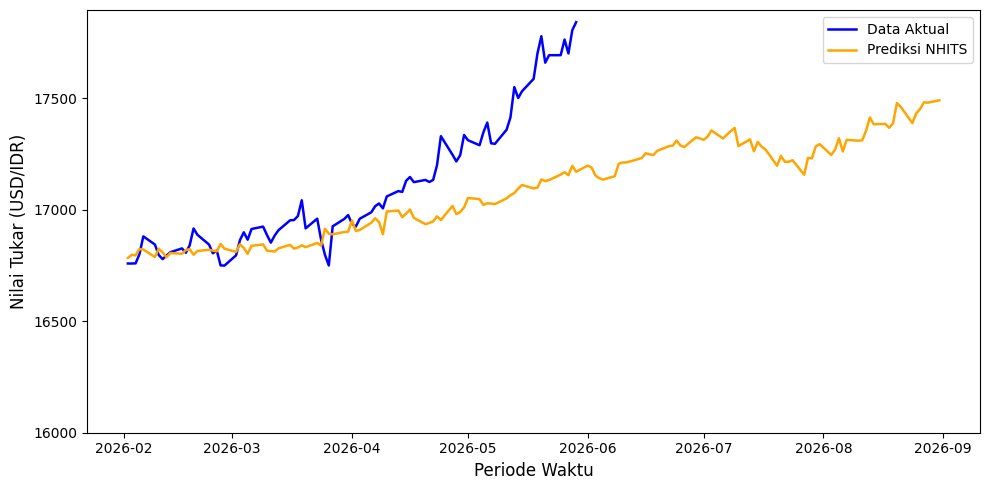

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(data_ftr['ds'], data_ftr['y'],
         color='blue',
         linewidth=1.8,
         label='Data Aktual')

plt.plot(fcst_future['ds'], fcst_future['NHITS'],
         color='orange',
         linewidth=1.8,
         label='Prediksi NHITS')

plt.xlabel('Periode Waktu', fontsize=12)
plt.ylabel('Nilai Tukar (USD/IDR)', fontsize=12)
plt.yticks(np.arange(16000, 18000, 500))
plt.grid(False)
plt.legend()

plt.tight_layout()

plt.show()